<a href="https://colab.research.google.com/github/ALISSONRABELOTEIXEIRA/Grupo-7_pbl_fase6/blob/main/Alisson_Vinicius_de_Souza_Rabelo_Teixeira_pbl_fase6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

===================================================================
#TREINAMENTO YOLO
===================================================================

##Conecta o Google Drive para acessar os arquivos.

In [144]:
# Importa o acesso ao Google Drive.
from google.colab import drive
# Conecta o Drive ao Colab.
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Baixa o YOLOv5 para o ambiente.

In [145]:
# Baixa o repositório do YOLOv5.
! git clone https://github.com/ultralytics/yolov5.git


fatal: destination path 'yolov5' already exists and is not an empty directory.


##Instala as dependências do YOLOv5.

In [146]:
# Instala as dependências do YOLOv5.
! pip install -r yolov5/requirements.txt


#Copia a configuração dos dados para o YOLOv5.

In [147]:
# Copia a configuração do conjunto de dados.
! cp /content/drive/MyDrive/Imagens_Cap1/Dataset/config.yaml yolov5/data/


#Treina e valida o modelo por 30 épocas.

In [148]:
# Treina o YOLOv5s por 30 épocas, com imagens de 640 pixels.
!python yolov5/train.py --data drive/MyDrive/Imagens_Cap1/Dataset/config.yaml --weights yolov5s.pt --img 640 --epochs 30


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791936140.620423   35203 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791936141.689186   35203 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791936141.689449   35203 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout

#Detecta objetos nas imagens de teste com o modelo mais recente.

In [149]:
# Importa funções para acessar pastas e arquivos.
import os
# Permite executar comandos externos.
import subprocess

# Define a função que localiza o treinamento mais recente.
def get_latest_train_run_folder():
    # Lista as pastas de treinamento.
    subfolders = [f.path for f in os.scandir('yolov5/runs/train') if f.is_dir()]
    # Seleciona a pasta com o maior valor de ctime.
    latest_folder = max(subfolders, key=os.path.getctime, default=None)
    # Retorna a pasta encontrada ou None.
    return latest_folder

# Busca o treinamento mais recente.
latest_run = get_latest_train_run_folder()

# Continua se houver uma pasta de treinamento.
if latest_run:
    # Mostra a pasta do modelo selecionado.
    print("Modelo utilizado:", latest_run)

    # Executa a detecção com os parâmetros abaixo.
    result = subprocess.run(
        # Chama o script de detecção.
        f'python yolov5/detect.py '
        # Carrega os melhores pesos do treinamento.
        f'--weights {latest_run}/weights/best.pt '
        # Define o tamanho de entrada como 640 pixels.
        f'--img 640 '
        # Aceita detecções com confiança mínima de 10%.
        f'--conf-thres 0.10 '
        # Usa as imagens da pasta de teste.
        f'--source drive/MyDrive/Imagens_Cap1/Dataset/test/ '
        # Informa a configuração do conjunto de dados.
        f'--data yolov5/data/config.yaml',
        # Executa o comando pelo shell.
        shell=True,
        # Captura as saídas do comando.
        capture_output=True,
        # Retorna as saídas como texto.
        text=True
    )

    # Exibe a saída padrão.
    print(result.stdout)
    # Exibe mensagens enviadas à saída de erro.
    print(result.stderr)

# Trata a ausência de uma pasta de treinamento.
else:
    # Informa que nenhum treinamento foi encontrado.
    print("Não foi possível encontrar a pasta de treinamento mais recente.")


Modelo utilizado: yolov5/runs/train/exp
detect: weights=['yolov5/runs/train/exp/weights/best.pt'], source=drive/MyDrive/Imagens_Cap1/Dataset/test/, data=yolov5/data/config.yaml, imgsz=[640, 640], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda1.JPG: 448x640 2 Pandas, 11.4ms
image 2/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda2.jpg: 576x640 1 Porco, 12.3ms
image 3/10 /content/

#Treina e valida um novo modelo por 60 épocas.

In [150]:
# Treina o YOLOv5s por 60 épocas, com imagens de 640 pixels.
!python yolov5/train.py --data drive/MyDrive/Imagens_Cap1/Dataset/config.yaml --weights yolov5s.pt --img 640 --epochs 60


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791936172.890182   35642 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791936173.951664   35642 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791936173.951944   35642 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout

#Repete a detecção nas imagens de teste com o modelo mais recente.

In [151]:
# Importa funções para acessar pastas e arquivos.
import os
# Permite executar comandos externos.
import subprocess

# Define a função que localiza o treinamento mais recente.
def get_latest_train_run_folder():
    # Lista as pastas de treinamento.
    subfolders = [f.path for f in os.scandir('yolov5/runs/train') if f.is_dir()]
    # Seleciona a pasta com o maior valor de ctime.
    latest_folder = max(subfolders, key=os.path.getctime, default=None)
    # Retorna a pasta encontrada ou None.
    return latest_folder

# Busca o treinamento mais recente.
latest_run = get_latest_train_run_folder()

# Continua se houver uma pasta de treinamento.
if latest_run:
    # Mostra a pasta do modelo selecionado.
    print("Modelo utilizado:", latest_run)

    # Executa a detecção com os parâmetros abaixo.
    result = subprocess.run(
        # Chama o script de detecção.
        f'python yolov5/detect.py '
        # Carrega os melhores pesos do treinamento.
        f'--weights {latest_run}/weights/best.pt '
        # Define o tamanho de entrada como 640 pixels.
        f'--img 640 '
        # Aceita detecções com confiança mínima de 10%.
        f'--conf-thres 0.10 '
        # Usa as imagens da pasta de teste.
        f'--source drive/MyDrive/Imagens_Cap1/Dataset/test/ '
        # Informa a configuração do conjunto de dados.
        f'--data yolov5/data/config.yaml',
        # Executa o comando pelo shell.
        shell=True,
        # Captura as saídas do comando.
        capture_output=True,
        # Retorna as saídas como texto.
        text=True
    )

    # Exibe a saída padrão.
    print(result.stdout)
    # Exibe mensagens enviadas à saída de erro.
    print(result.stderr)

# Trata a ausência de uma pasta de treinamento.
else:
    # Informa que nenhum treinamento foi encontrado.
    print("Não foi possível encontrar a pasta de treinamento mais recente.")


Modelo utilizado: yolov5/runs/train/exp2
detect: weights=['yolov5/runs/train/exp2/weights/best.pt'], source=drive/MyDrive/Imagens_Cap1/Dataset/test/, data=yolov5/data/config.yaml, imgsz=[640, 640], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda1.JPG: 448x640 1 Panda, 11.6ms
image 2/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda2.jpg: 576x640 1 Panda, 12.4ms
image 3/10 /content

#Exibe as imagens com as detecções do modelo.

Imagem: panda1.JPG


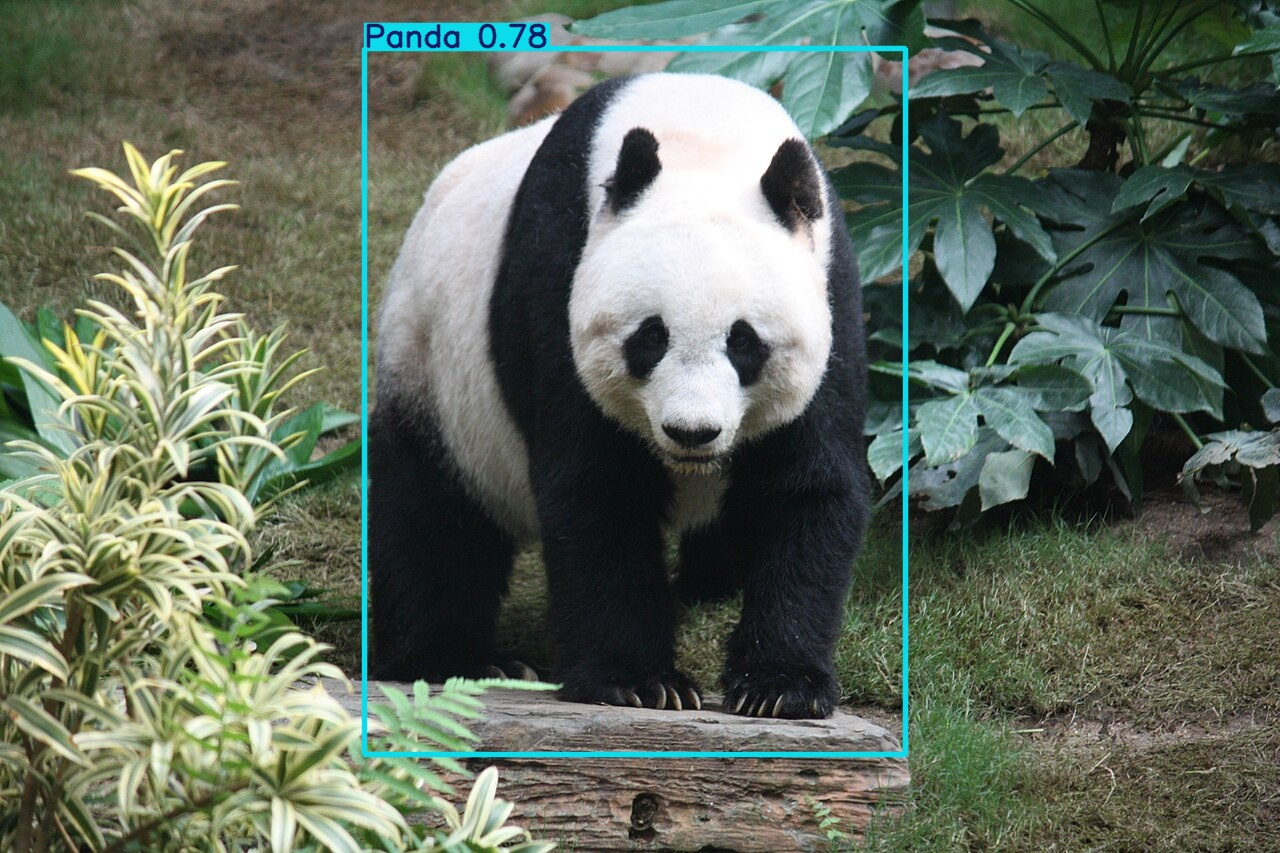

Imagem: panda2.jpg


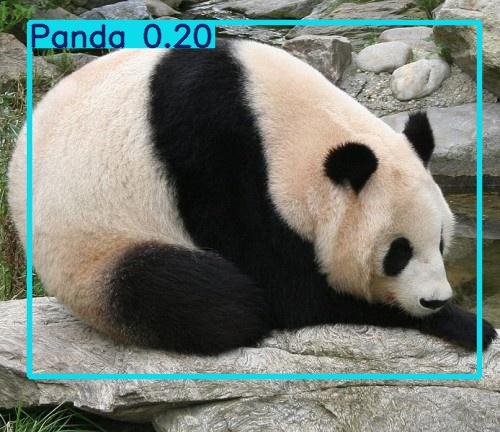

Imagem: panda3.jpg


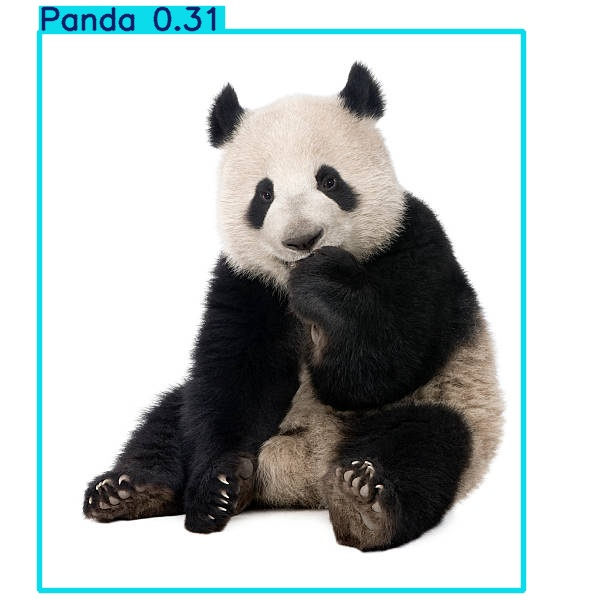

Imagem: panda4.jpg


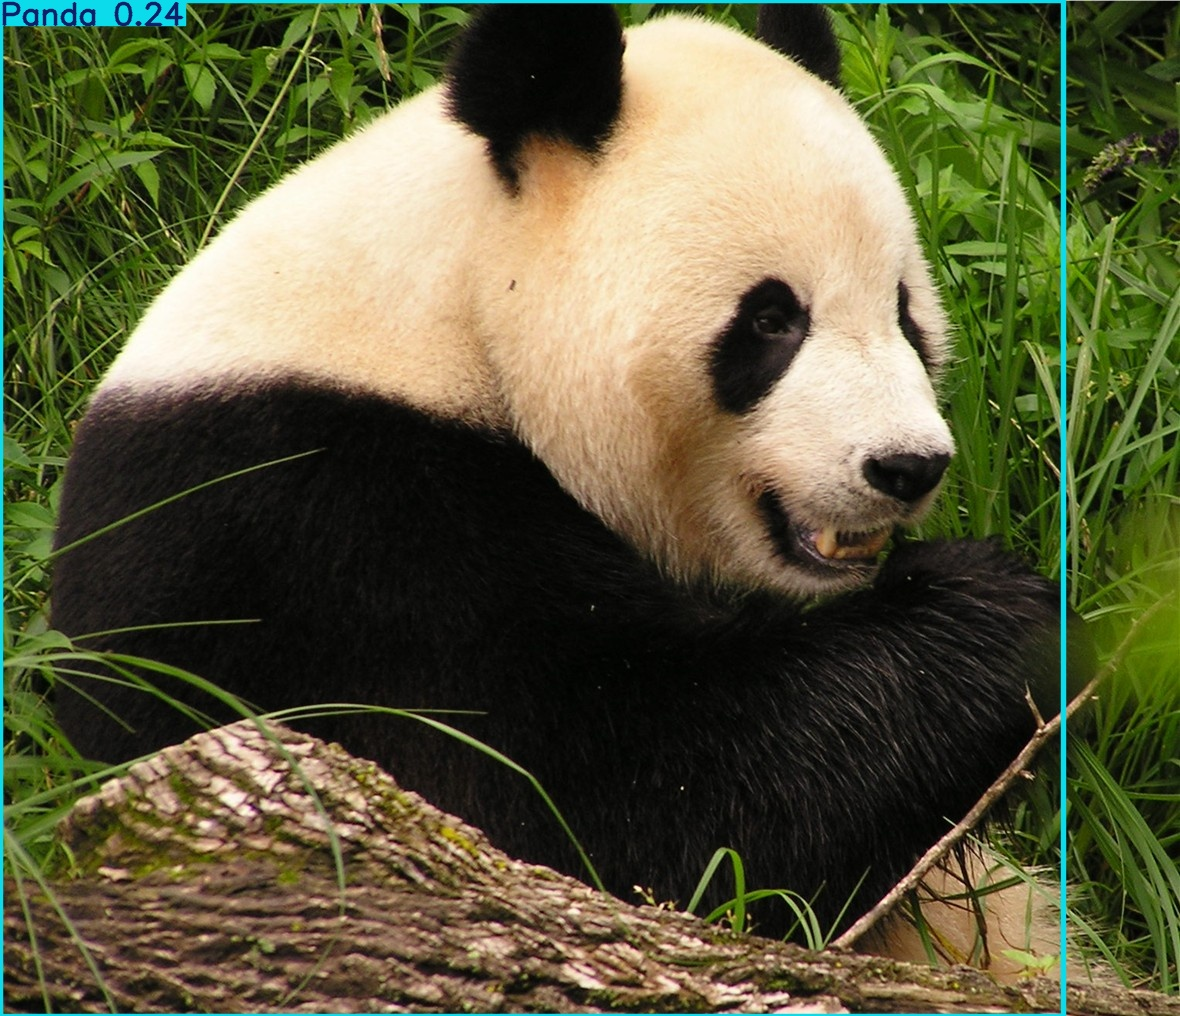

Imagem: panda5.jpg


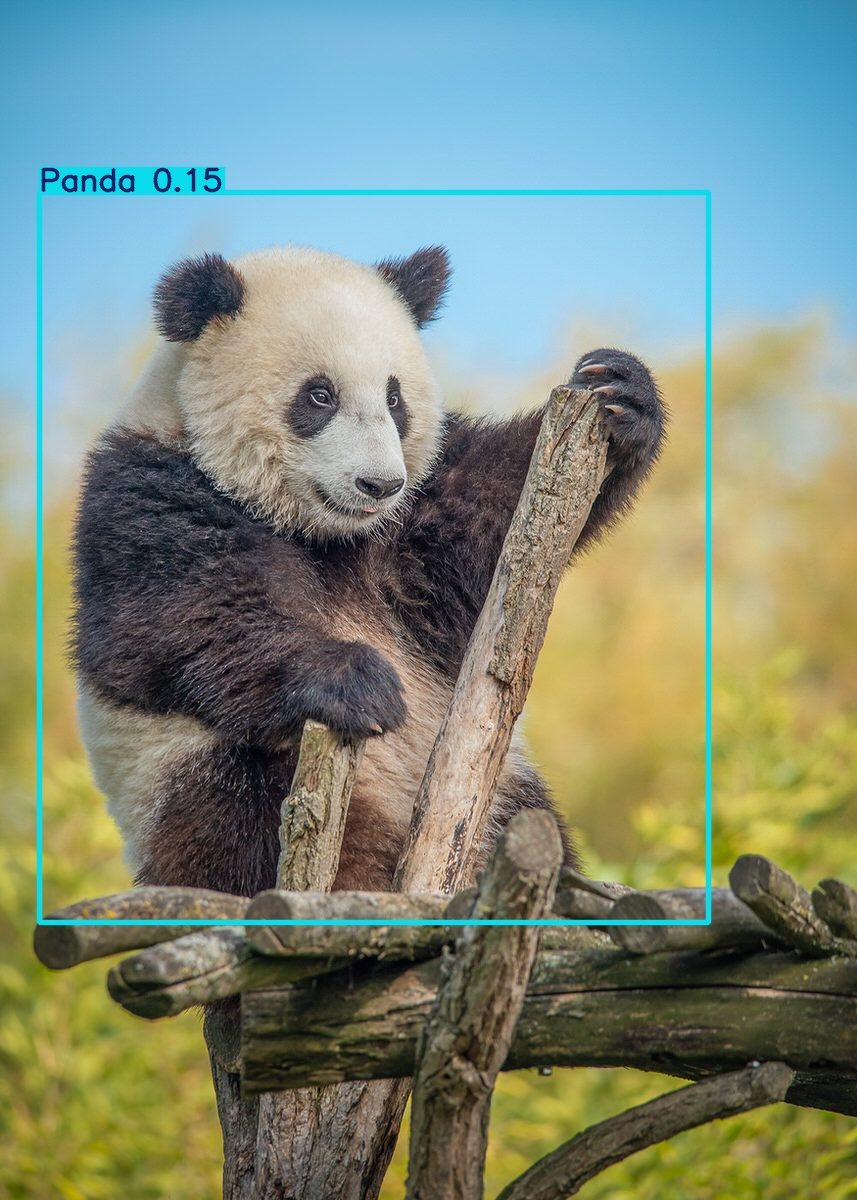

Imagem: porco1.jpg


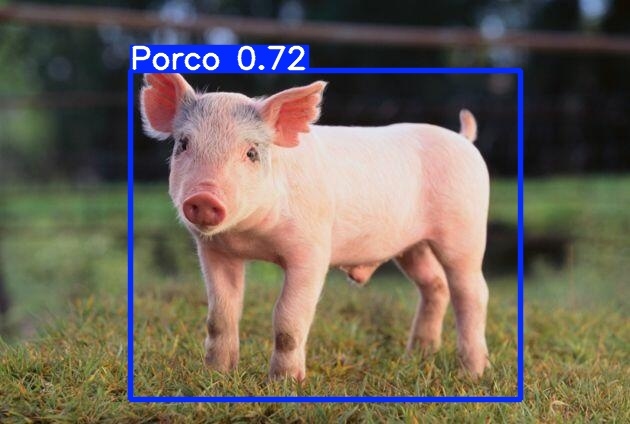

Imagem: porco2.jpg


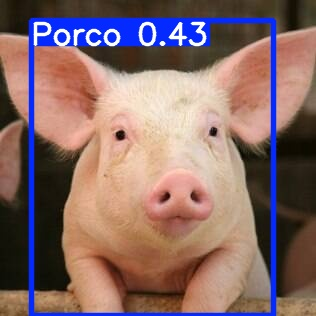

Imagem: porco3.jpg


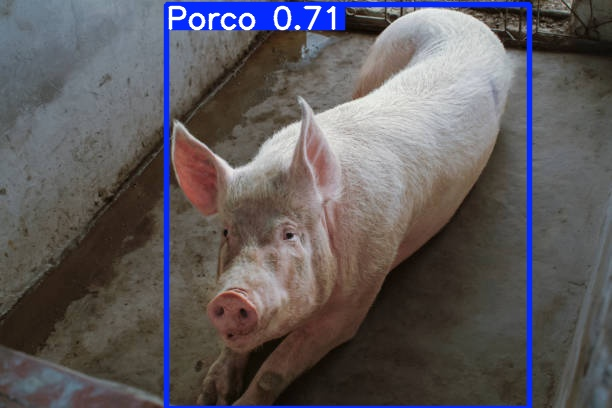

Imagem: porco4.jpg


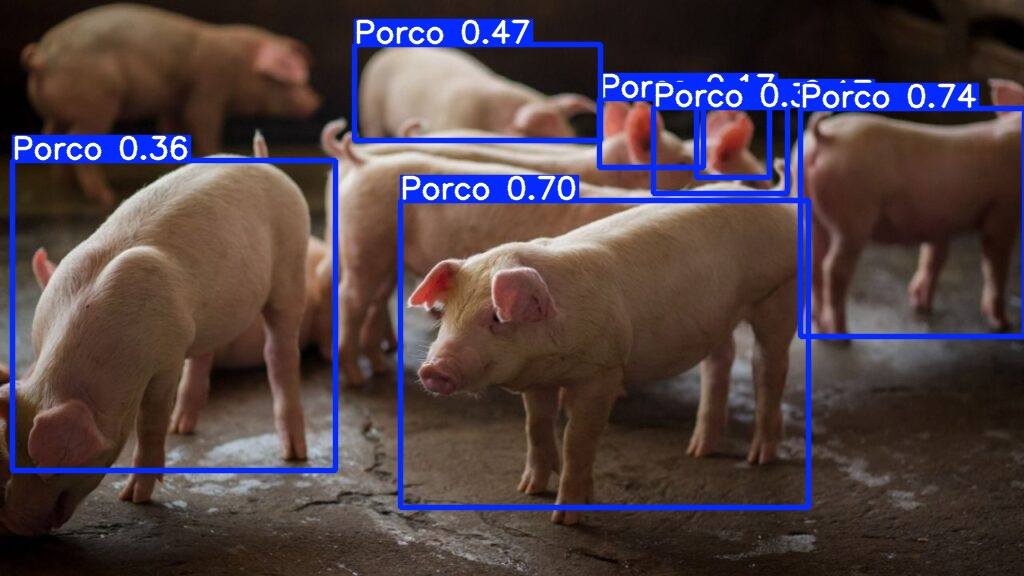

Imagem: porco5.jpg


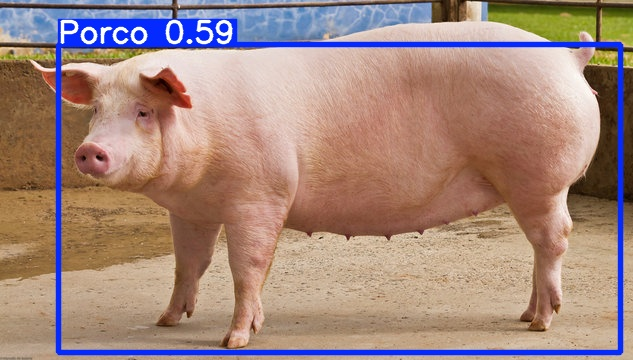

In [152]:
from IPython.display import Image, display
from pathlib import Path

# Pasta onde estão as imagens detectadas
pasta = Path('/content/yolov5/runs/detect/exp2')

# Listar os arquivos de imagem da pasta
imagens = sorted(
    arquivo for arquivo in pasta.glob('*')
    if arquivo.suffix.lower() in {'.jpg', '.jpeg', '.png'}
)

# Exibir todas as imagens
for imagem in imagens:
    print(f"Imagem: {imagem.name}")
    display(Image(filename=str(imagem)))

#Passo a passo: Treinamento, Validação e treino

## 1. Treinamento
- Acessar os dados no Google Drive e instalar o YOLOv5.
- Carregar o `config.yaml`, que indica os dados e as classes.
- Treinar o YOLOv5s com imagens de 640 pixels em dois experimentos: 30 e 60 épocas.
- Ajustar os pesos para aprender a detectar porcos e pandas.

## 2. Validação
- Avaliar o modelo nos dados de validação durante o treinamento, sem atualizar os pesos.
- Acompanhar precisão, recall e mAP para verificar a qualidade das detecções.
- Comparar os experimentos: o de 60 épocas apresentou melhores métricas de validação.
- Salvar o melhor modelo de cada treinamento em `best.pt`.

## 3. Teste
- Carregar o `best.pt` do treinamento mais recente.
- Executar a detecção nas 10 imagens da pasta de teste, com confiança mínima de 10%.
- Exibir as imagens e observar classes e caixas detectadas.
- Nesta etapa, o notebook permite avaliação visual; não calcula precisão, recall ou mAP de teste.


##Conclusão das épocas e resultados

#Evidências YOLO

### Matriz de confusão — exp

Mostra acertos, confusões entre classes e falhas de detecção.

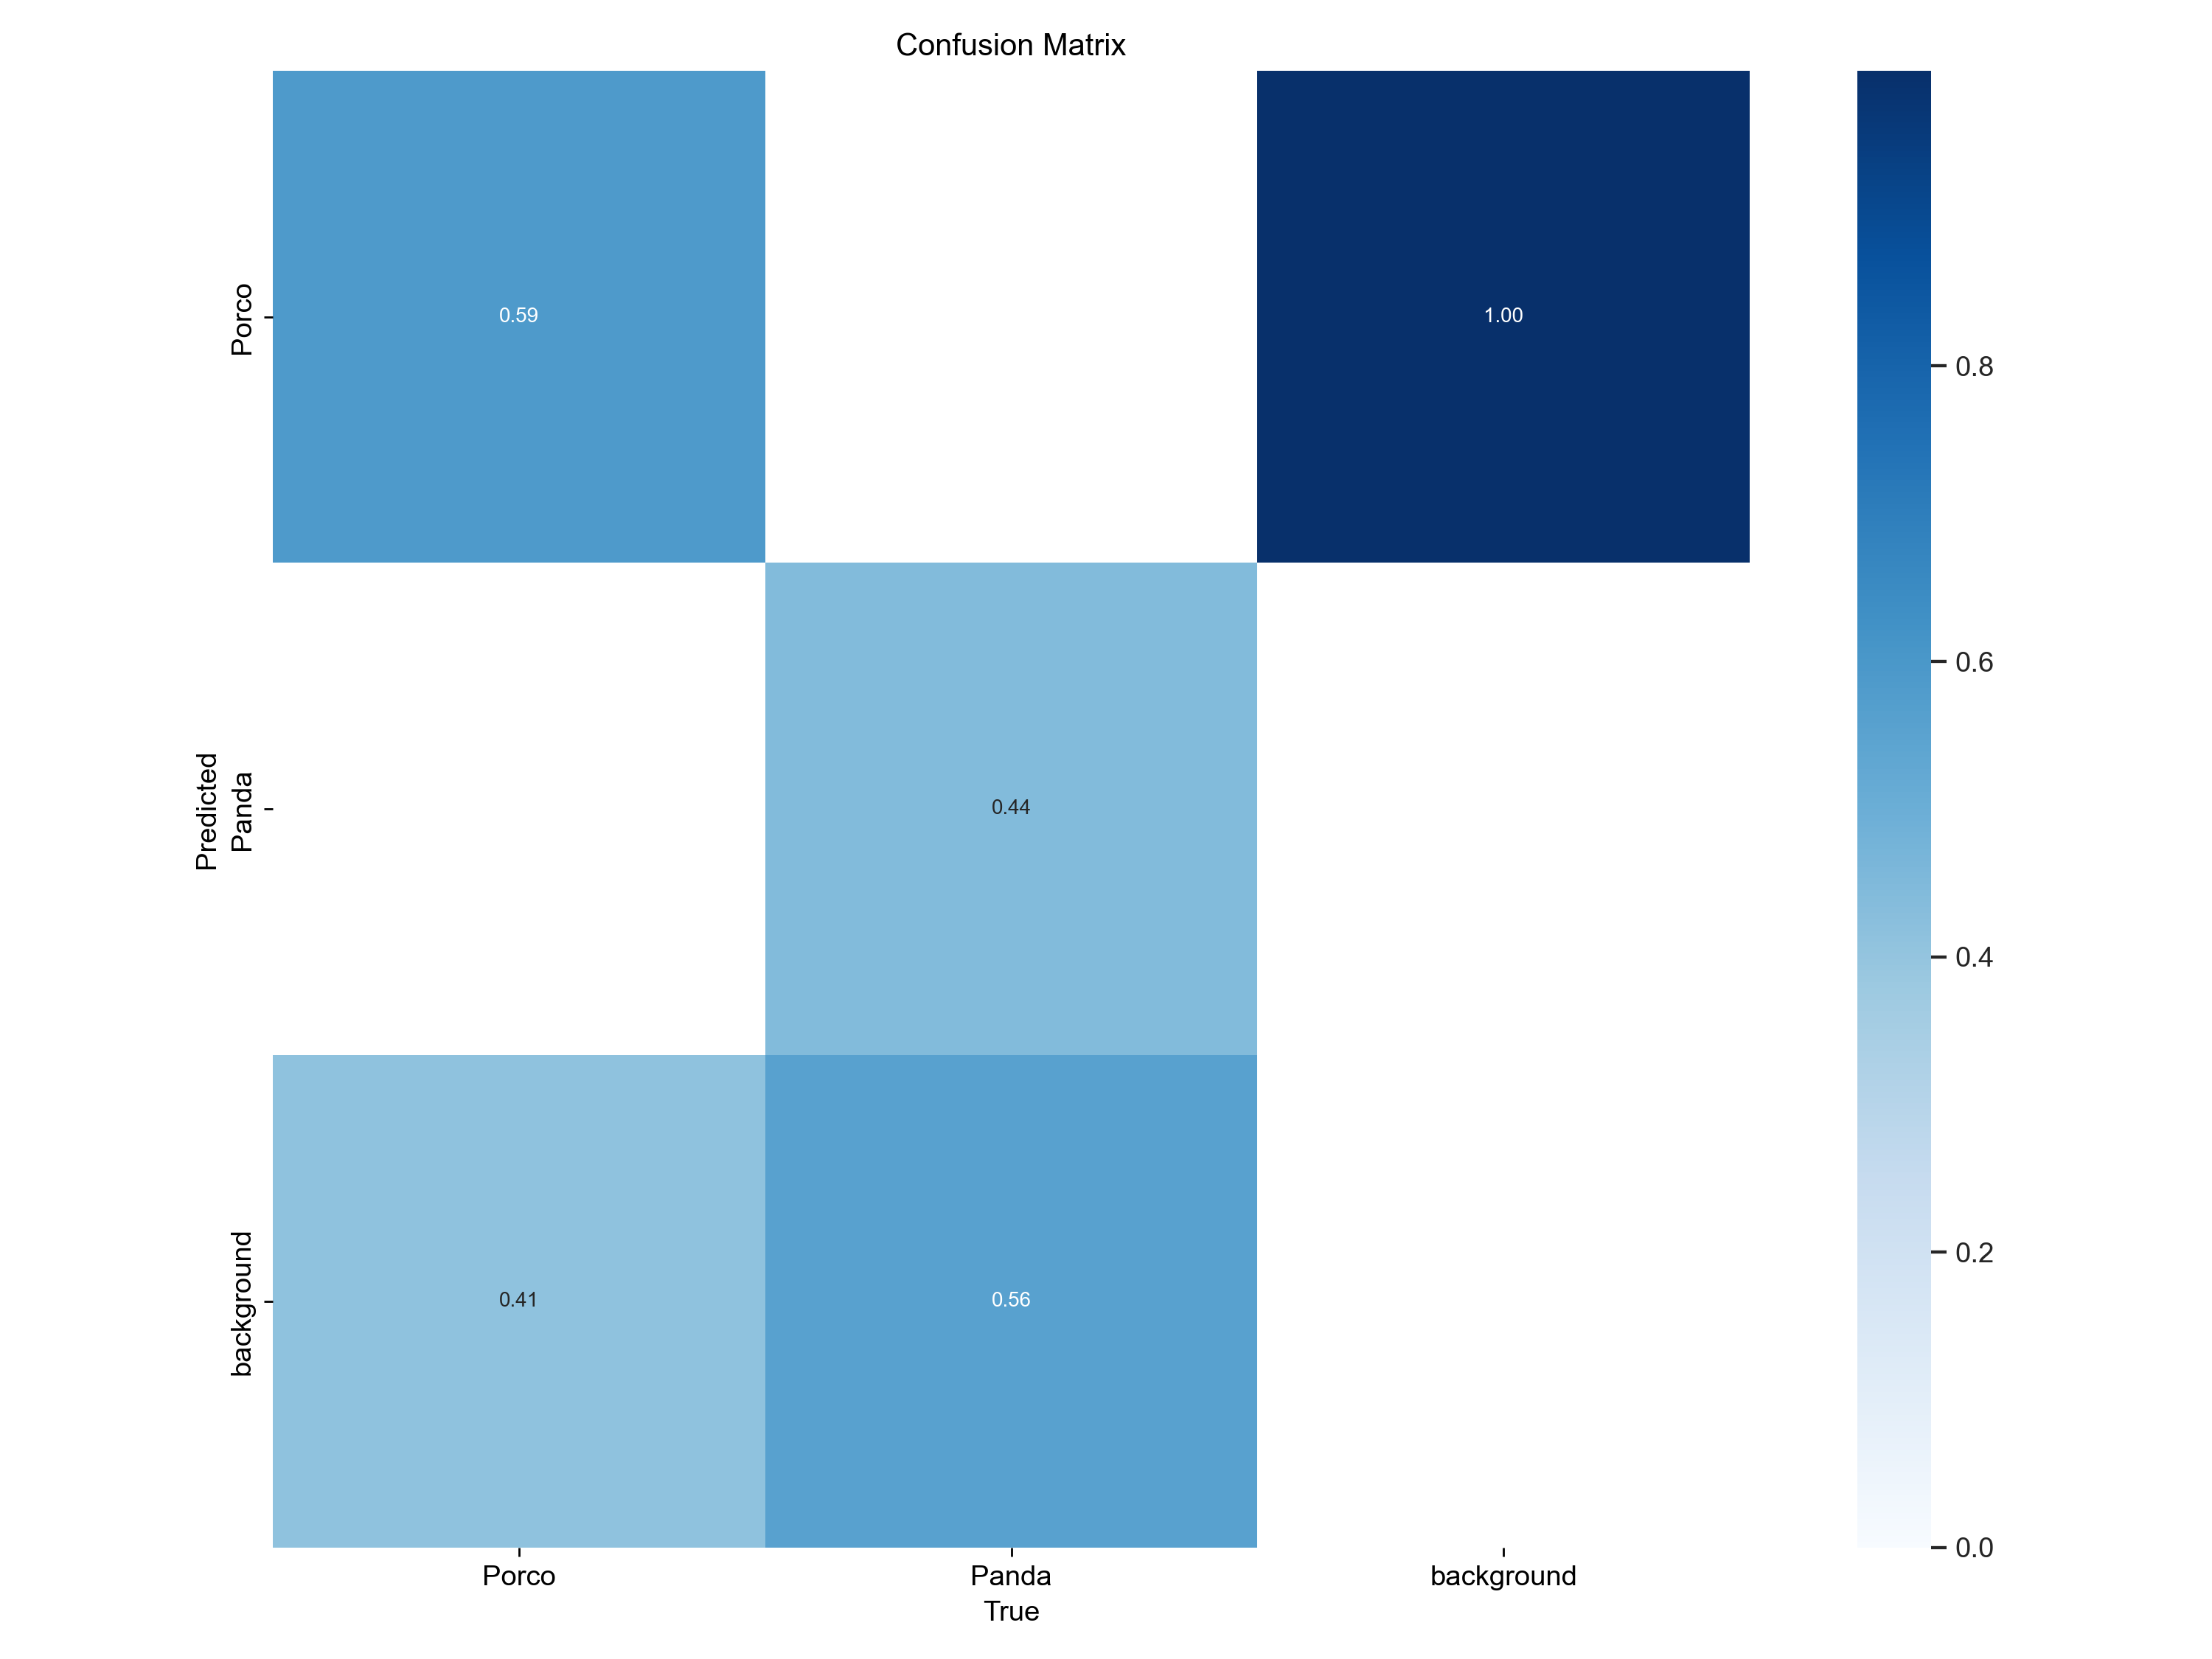

### Evolução do treinamento — exp

Mostra as perdas, precisão, recall e mAP ao longo das épocas.

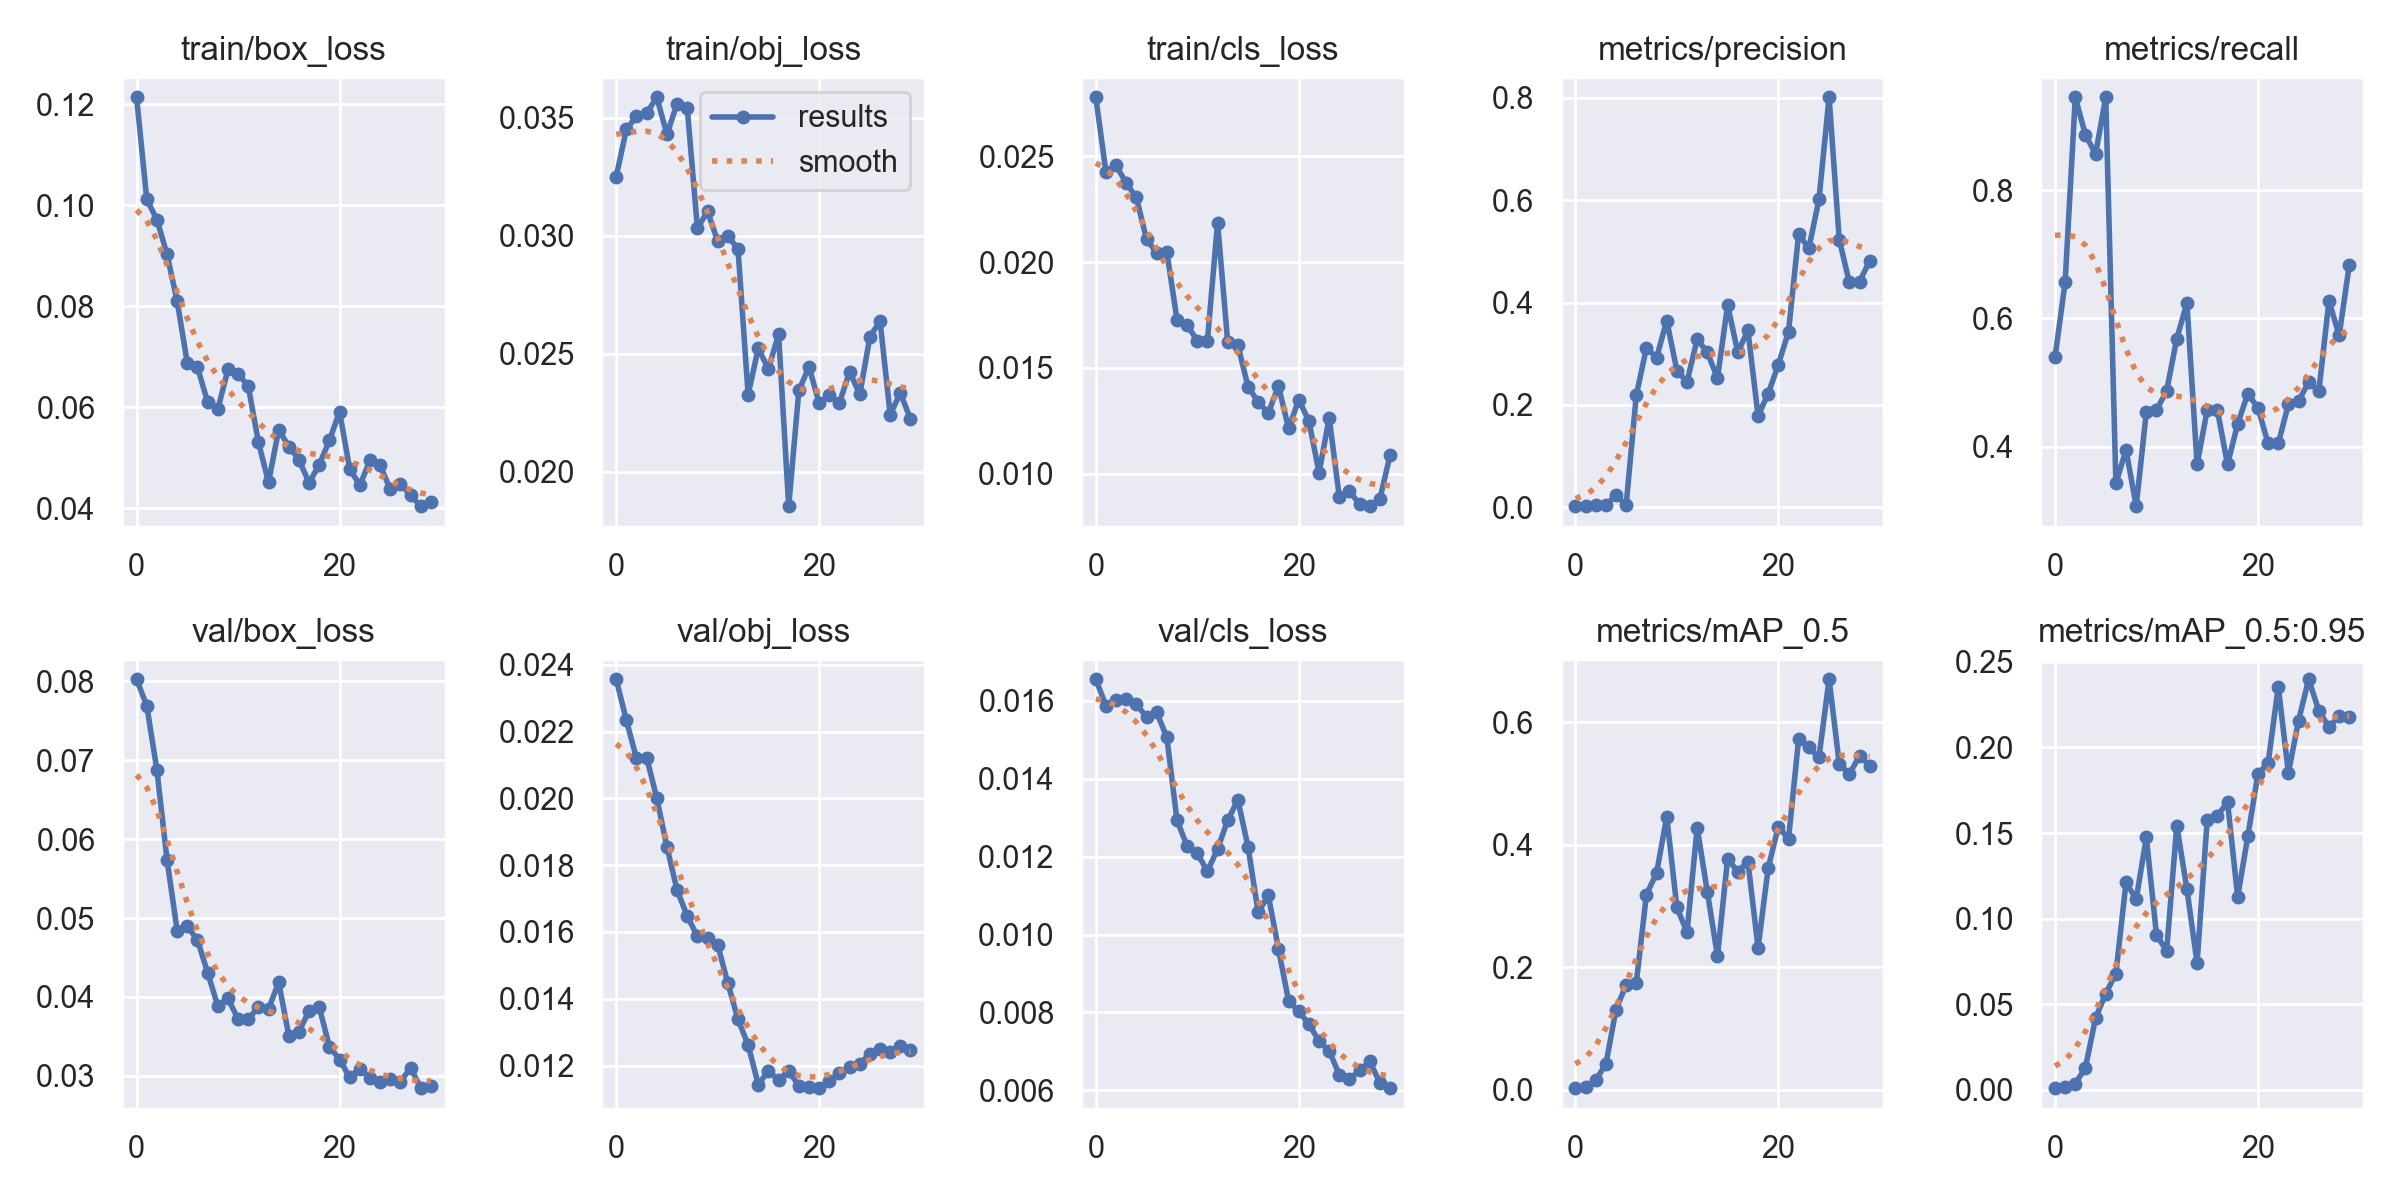

### Curva de precisão e recall — exp

Mostra a relação entre precisão e recall, com AP por classe e mAP50 geral.

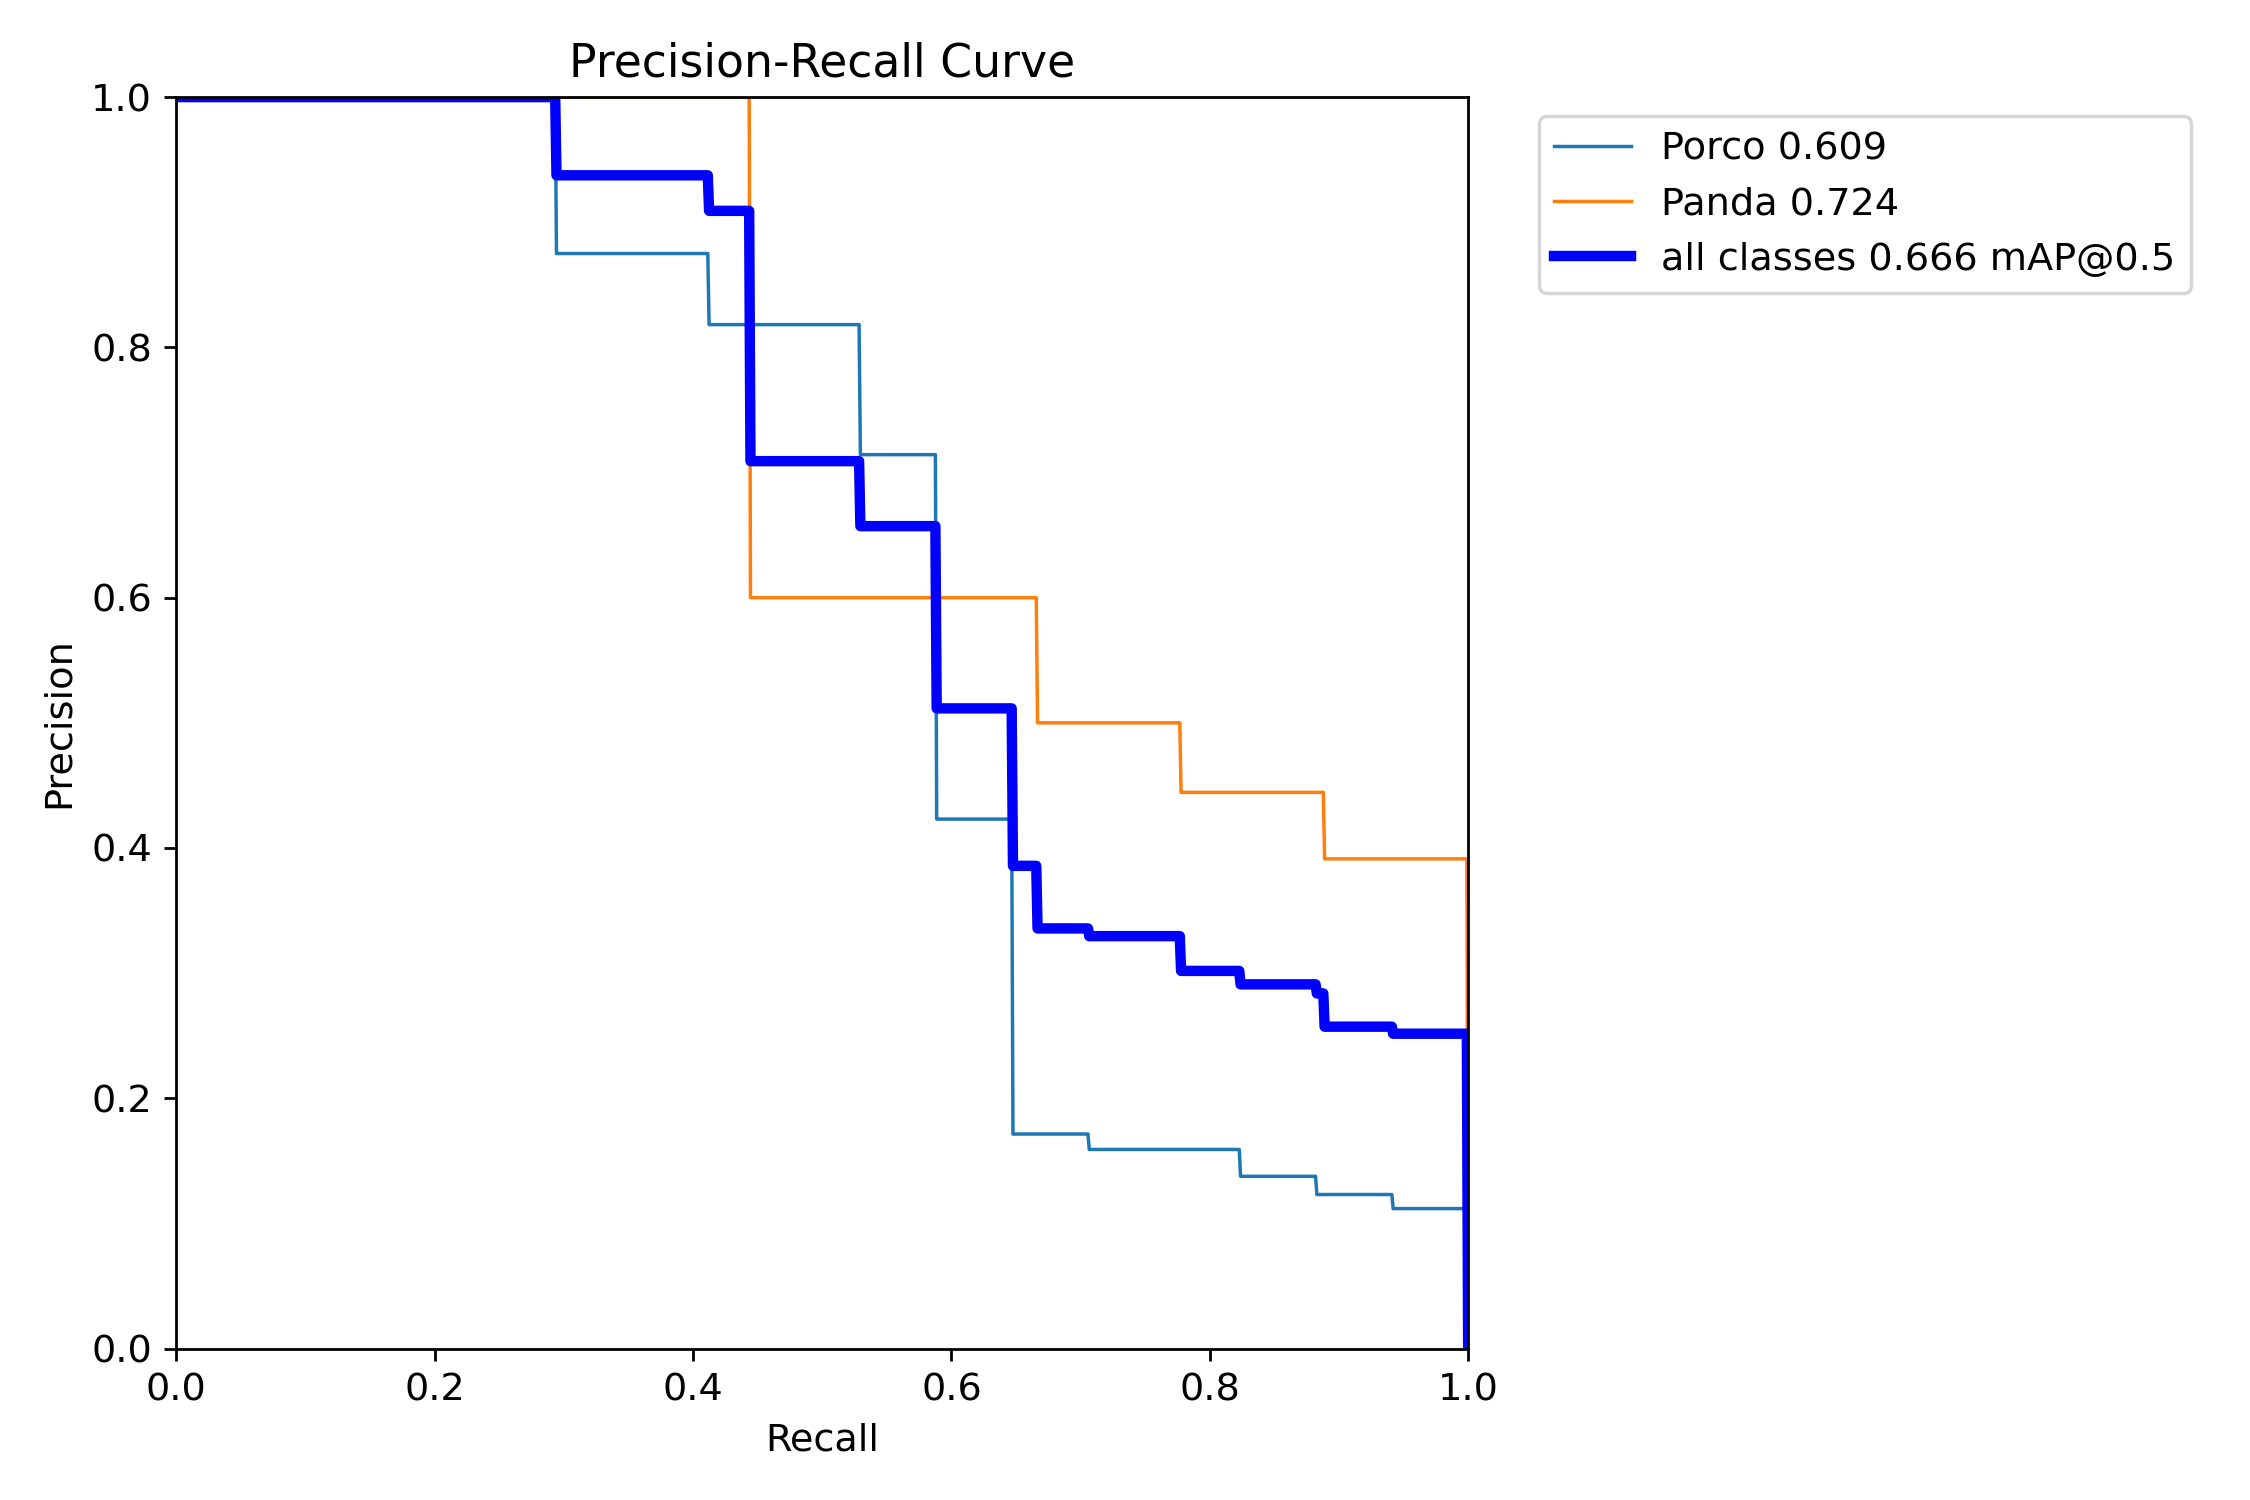

In [153]:
from IPython.display import Image, display, Markdown
imagens = [
    (
        '/content/yolov5/runs/train/exp/confusion_matrix.png',
        'Matriz de confusão — exp',
        'Mostra acertos, confusões entre classes e falhas de detecção.'
    ),
    (
        '/content/yolov5/runs/train/exp/results.png',
        'Evolução do treinamento — exp',
        'Mostra as perdas, precisão, recall e mAP ao longo das épocas.'
    ),
    (
        '/content/yolov5/runs/train/exp/PR_curve.png',
        'Curva de precisão e recall — exp',
        'Mostra a relação entre precisão e recall, com AP por classe e mAP50 geral.'
    ),
]
for caminho, titulo, descricao in imagens:
    display(Markdown(f'### {titulo}\n\n{descricao}'))
    display(Image(filename=caminho, width=800))



Resultados gerais de **validação** do melhor modelo de cada treinamento:

| Métrica | 30 épocas | 60 épocas | Aumento |
|---|---:|---:|---:|
| Precisão | 63,9% | 84,3% | 20,4 pontos percentuais |
| Recall | 48,2% | 62,4% | 14,2 pontos percentuais |
| mAP50 | 58,9% | 77,3% | 18,4 pontos percentuais |
| mAP50-95 | 25,9% | 37,6% | 11,7 pontos percentuais |

- **Precisão:** com 60 épocas, uma proporção maior das detecções estava correta.
- **Recall:** o modelo conseguiu identificar uma proporção maior dos objetos existentes.
- **mAP50:** houve melhora na qualidade geral das detecções.
- **mAP50-95:** houve melhora também sob critérios mais rigorosos de localização das caixas.

**Conclusão:** o treinamento de 60 épocas apresentou melhores resultados nas quatro métricas de validação, embora ainda haja espaço para melhorar a identificação e a localização dos objetos.

# Relatório de resultados e conclusões

### Achados
Nos gráficos fornecidos nas pastas de 30 e 60 épocas, o **mAP50 aumentou de 55,4% para 84,6%**. A melhora foi maior para pandas: o AP50 passou de 52,2% para 99,5%; para porcos, de 58,6% para 69,7%. Esses valores vêm das curvas de precisão e recall dessas pastas e diferem dos registros anteriores do notebook.

### Pontos fortes e limitações
As curvas mostram redução das perdas de treinamento e melhora na localização e classificação durante a validação. As matrizes de confusão indicam menos objetos não detectados, principalmente pandas. Ainda persistem falhas na detecção de porcos, falsos positivos e limitações na localização precisa das caixas. A perda de presença de objetos na validação oscila e aumenta em parte do treino de 60 épocas, exigindo atenção à generalização.

### Conclusão
O treinamento de **60 épocas apresentou melhor desempenho**, mas isso não garante o mesmo resultado em novas imagens. A validação pequena e o teste apenas visual limitam o trabalho. Ampliar os dados e calcular métricas em um teste independente e anotado são os próximos passos.


=====================================================================
=====================================================================

===================================================================
#TREINAMENTO CNN
===================================================================

#Importa as bibliotecas utilizadas no projeto.

In [154]:
# Importa o TensorFlow.
import tensorflow as tf
# Importa o Keras.
from tensorflow import keras

# Importa operações com arrays.
import numpy as np
# Importa os gráficos.
import matplotlib.pyplot as plt
# Importa o tratamento de imagens.
from PIL import Image, ImageOps

#Conecta o Drive e define a pasta dos dados.

In [155]:
# Importa o acesso ao Drive.
from google.colab import drive
# Importa caminhos de arquivos.
from pathlib import Path

# Conecta o Google Drive.
drive.mount('/content/drive')

# Define a pasta do dataset.
PASTA = Path('/content/drive/MyDrive/Imagens_Cap1/Dataset')
# Define as classes.
CLASSES = ['Porco', 'Panda']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Carrega as imagens e seus rótulos.

In [156]:
# Importa operações com arrays.
import numpy as np
# Importa o tratamento de imagens.
from PIL import Image, ImageOps

# Define o carregamento dos dados.
def carregar_dados(particao):
    # Inicia as listas de dados.
    imagens, rotulos = [], []

    # Percorre os arquivos em ordem.
    for caminho in sorted((PASTA / 'images' / particao).iterdir()):
        # Filtra os formatos de imagem.
        if caminho.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            # Ignora arquivos de outros formatos.
            continue

        # Localiza a anotação da imagem.
        anotacao = PASTA / 'labels' / particao / f'{caminho.stem}.txt'
        # Reúne as classes anotadas.
        classes = {
            # Lê o identificador da classe.
            int(linha.split()[0])
            # Percorre as anotações.
            for linha in anotacao.read_text().splitlines()
            # Ignora linhas vazias.
            if linha.strip()
        }

        # Verifica se há uma classe válida.
        if len(classes) != 1 or not classes.issubset({0, 1}):
            # Interrompe se houver classe inválida.
            raise ValueError(f'Confira as classes de {caminho.name}')

        # Abre a imagem.
        with Image.open(caminho) as imagem:
            # Corrige a orientação e converte para RGB.
            imagem = ImageOps.exif_transpose(imagem).convert('RGB')
            # Redimensiona para 150 × 150 pixels.
            imagem = imagem.resize((150, 150))
            # Armazena os pixels como array.
            imagens.append(np.asarray(imagem, dtype=np.float32))

        # Armazena a classe da imagem.
        rotulos.append(classes.pop())

    # Retorna imagens e rótulos.
    return np.stack(imagens), np.array(rotulos, dtype=np.int32)

# Carrega a base de treinamento.
x_base, y_base = carregar_dados('train')
# Carrega os dados de validação.
x_val, y_val = carregar_dados('val')

# Mostra a quantidade de imagens.
print('Imagens carregadas:', len(x_base))

Imagens carregadas: 70


#Separa os dados de treino e teste.

In [157]:
# Importa a divisão dos dados.
from sklearn.model_selection import train_test_split

# Carrega a base de treinamento.
x_base, y_base = carregar_dados('train')
# Carrega as imagens e classes de validação.
val_images, val_labels = carregar_dados('val')

# Divide a base em treino e teste.
train_images, test_images, train_labels, test_labels = train_test_split(
    # Fornece as imagens.
    x_base,
    # Fornece os rótulos.
    y_base,
    # Reserva 20% para teste.
    test_size=0.2,
    # Fixa a aleatoriedade da divisão.
    random_state=42,
    # Mantém a proporção das classes.
    stratify=y_base
)

# Define os nomes das classes.
class_names = ['Porco', 'Panda']

# Mostra as dimensões do treino.
print('Formato do treino:', train_images.shape)
# Mostra a quantidade de rótulos.
print('Quantidade de rótulos:', len(train_labels))
# Exibe as classes do treino.
print('Rótulos do treino:', train_labels)
# Mostra as dimensões do teste.
print('Formato do teste:', test_images.shape)
# Mostra a quantidade de rótulos de teste.
print('Quantidade de rótulos de teste:', len(test_labels))


Formato do treino: (56, 150, 150, 3)
Quantidade de rótulos: 56
Rótulos do treino: [0 1 1 0 1 0 0 1 0 0 1 1 0 1 1 1 1 0 1 1 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 0
 1 0 1 0 0 1 0 1 0 0 1 1 0 1 0 1 1 0 0]
Formato do teste: (14, 150, 150, 3)
Quantidade de rótulos de teste: 14


#Normaliza os pixels das imagens entre 0 e 1.

In [158]:
# Normaliza as imagens de treino.
train_images = train_images / 255.0
# Normaliza as imagens de validação.
val_images = val_images / 255.0
# Normaliza as imagens de teste.
test_images = test_images / 255.0


#Cria e configura a CNN do zero.

In [159]:
# Importa o Keras.
from tensorflow import keras

# Fixa a semente de aleatoriedade.
keras.utils.set_random_seed(42)

# Cria a CNN do zero.
model = keras.Sequential([
    # Define a entrada RGB de 150 × 150.
    keras.Input(shape=(150, 150, 3)),

    # Extrai características com 16 filtros.
    keras.layers.Conv2D(16, 3, activation="relu", padding="same"),
    # Reduz as dimensões dos mapas.
    keras.layers.MaxPooling2D(2),

    # Extrai características com 32 filtros.
    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    # Reduz as dimensões dos mapas.
    keras.layers.MaxPooling2D(2),

    # Extrai características com 64 filtros.
    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    # Reduz as dimensões dos mapas.
    keras.layers.MaxPooling2D(2),

    # Transforma os mapas em um vetor.
    keras.layers.Flatten(),
    # Combina as características aprendidas.
    keras.layers.Dense(32, activation="relu"),
    # Desativa 30% das entradas durante o treino.
    keras.layers.Dropout(0.3),
    # Produz as probabilidades das duas classes.
    keras.layers.Dense(2, activation="softmax")
])

# Configura o treinamento.
model.compile(
    # Seleciona o otimizador Adam.
    optimizer="adam",
    # Define a perda para rótulos inteiros.
    loss="sparse_categorical_crossentropy",
    # Acompanha a acurácia.
    metrics=["accuracy"]
)

# Exibe a estrutura da rede.
model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │       663,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687,234 (2.62 MB)

 Trainable params: 687,234 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

#Treina a CNN por 10 épocas.

In [160]:
# Treina o modelo por 10 épocas.
model.fit(train_images, train_labels, epochs=10)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.5536 - loss: 0.7609
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5357 - loss: 0.6849
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5000 - loss: 0.6875
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6964 - loss: 0.6340
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7857 - loss: 0.5947
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8571 - loss: 0.5391
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8571 - loss: 0.4163
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8214 - loss: 0.3735
Epoch 9/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8929 - loss: 0.3197
Epoch 10/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8393 - loss: 0.3122


#Avalia a perda, a acurácia e a taxa de erro no teste.

In [161]:
# Calcula perda e acurácia no teste.
test_loss, test_acc = model.evaluate(
    # Fornece os dados sem mostrar progresso.
    test_images, test_labels, verbose=0
)

# Mostra a perda no teste.
print(f"Perda no teste: {test_loss:.4f}")
# Mostra a porcentagem de acertos.
print(f"Acurácia no teste: {test_acc:.2%}")
# Mostra a porcentagem de erros.
print(f"Taxa de erro: {1 - test_acc:.2%}")


Perda no teste: 0.2371
Acurácia no teste: 85.71%
Taxa de erro: 14.29%


#Exibe as imagens de teste com as previsões.

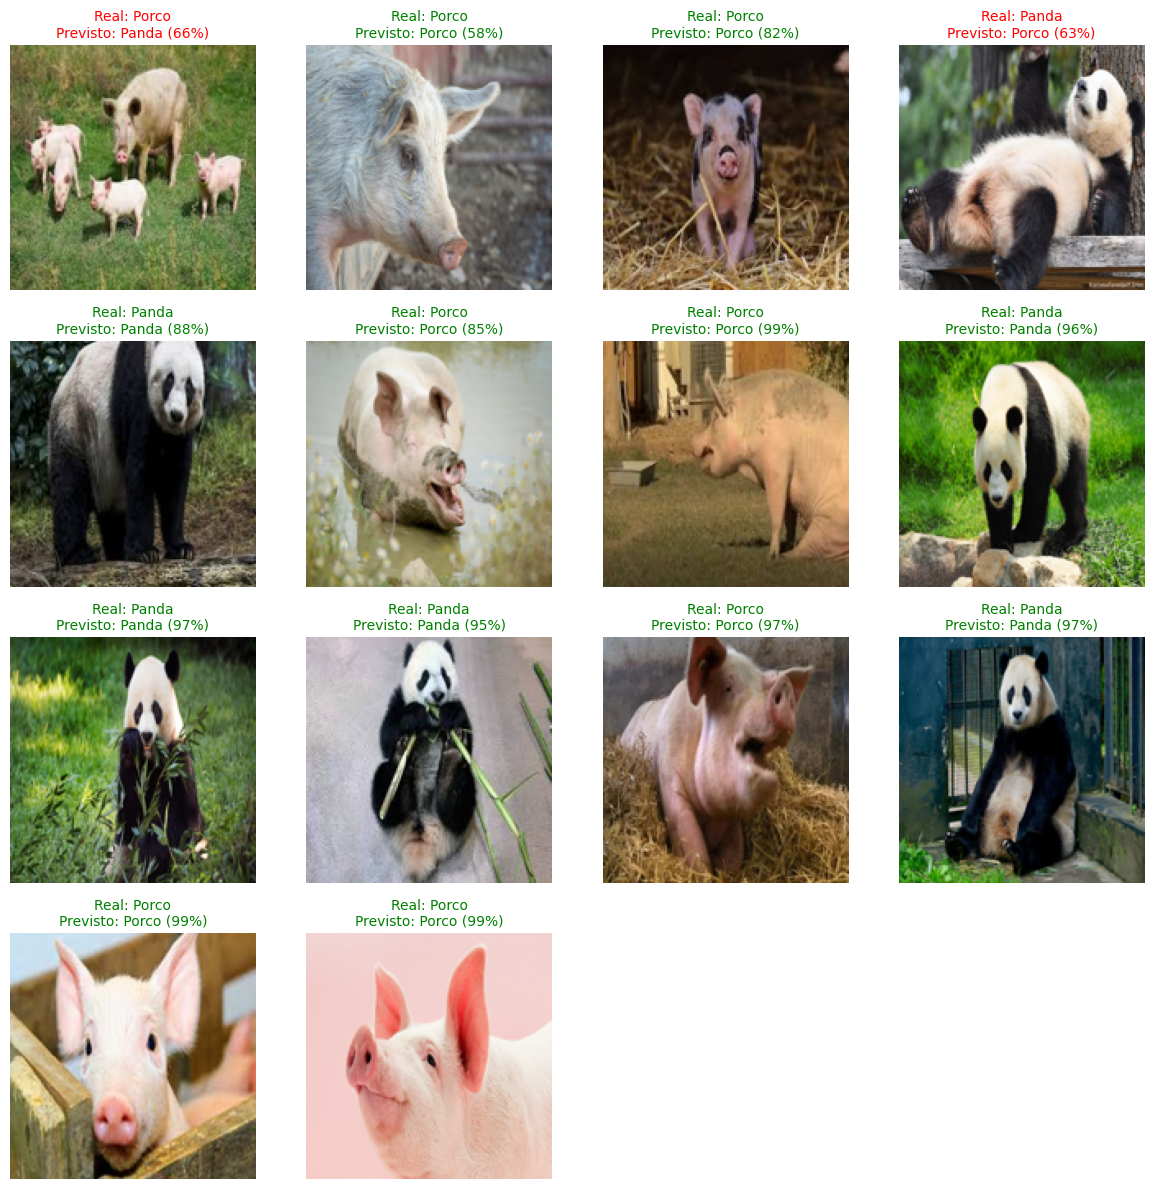

In [162]:
# Calcula as probabilidades no teste.
previsoes = model.predict(test_images, verbose=0)
# Seleciona a classe mais provável.
classes_previstas = np.argmax(previsoes, axis=1)

# Define os nomes das classes.
class_names = ['Porco', 'Panda']

# Define quatro colunas de imagens.
colunas = 4
# Calcula a quantidade de linhas.
linhas = (len(test_images) + colunas - 1) // colunas
# Define o tamanho da figura.
plt.figure(figsize=(12, linhas * 3))

# Percorre as imagens de teste.
for i in range(len(test_images)):
    # Seleciona a posição da imagem.
    plt.subplot(linhas, colunas, i + 1)

    # Exibe a imagem normalizada.
    plt.imshow(test_images[i])

    # Obtém a classe correta.
    real = int(test_labels[i])
    # Obtém a classe prevista.
    prevista = int(classes_previstas[i])
    # Obtém a confiança da previsão.
    confianca = previsoes[i][prevista]

    # Monta o título da imagem.
    plt.title(
        # Informa a classe correta.
        f"Real: {class_names[real]}\n"
        # Informa a previsão e sua confiança.
        f"Previsto: {class_names[prevista]} ({confianca:.0%})",
        # Usa verde para acerto e vermelho para erro.
        color='green' if real == prevista else 'red',
        # Define o tamanho do texto.
        fontsize=10
    )
    # Oculta os eixos.
    plt.axis('off')

# Ajusta o espaçamento.
plt.tight_layout()
# Mostra a figura.
plt.show()


# PASSO A PASSO

## 1. Criação da CNN
- Definir a entrada: imagens RGB de 150 × 150 pixels.
- Criar camadas de convolução, pooling e classificação.
- Configurar duas classes: Porco e Panda, com pesos inicialmente aleatórios.

## 2. Treinamento
- Utilizar as imagens de treino normalizadas e seus rótulos.
- Treinar por 10 épocas, ajustando os pesos automaticamente.
- Acompanhar a perda e a acurácia do treino.

## 3. Teste
- Avaliar o modelo nas imagens reservadas para teste.
- Calcular perda, acurácia e taxa de erro.
- Exibir as imagens e comparar as classes previstas com as reais.


#Evidências CNN

### Matriz de confusão

Mostra acertos, confusões entre classes e falhas de detecção.

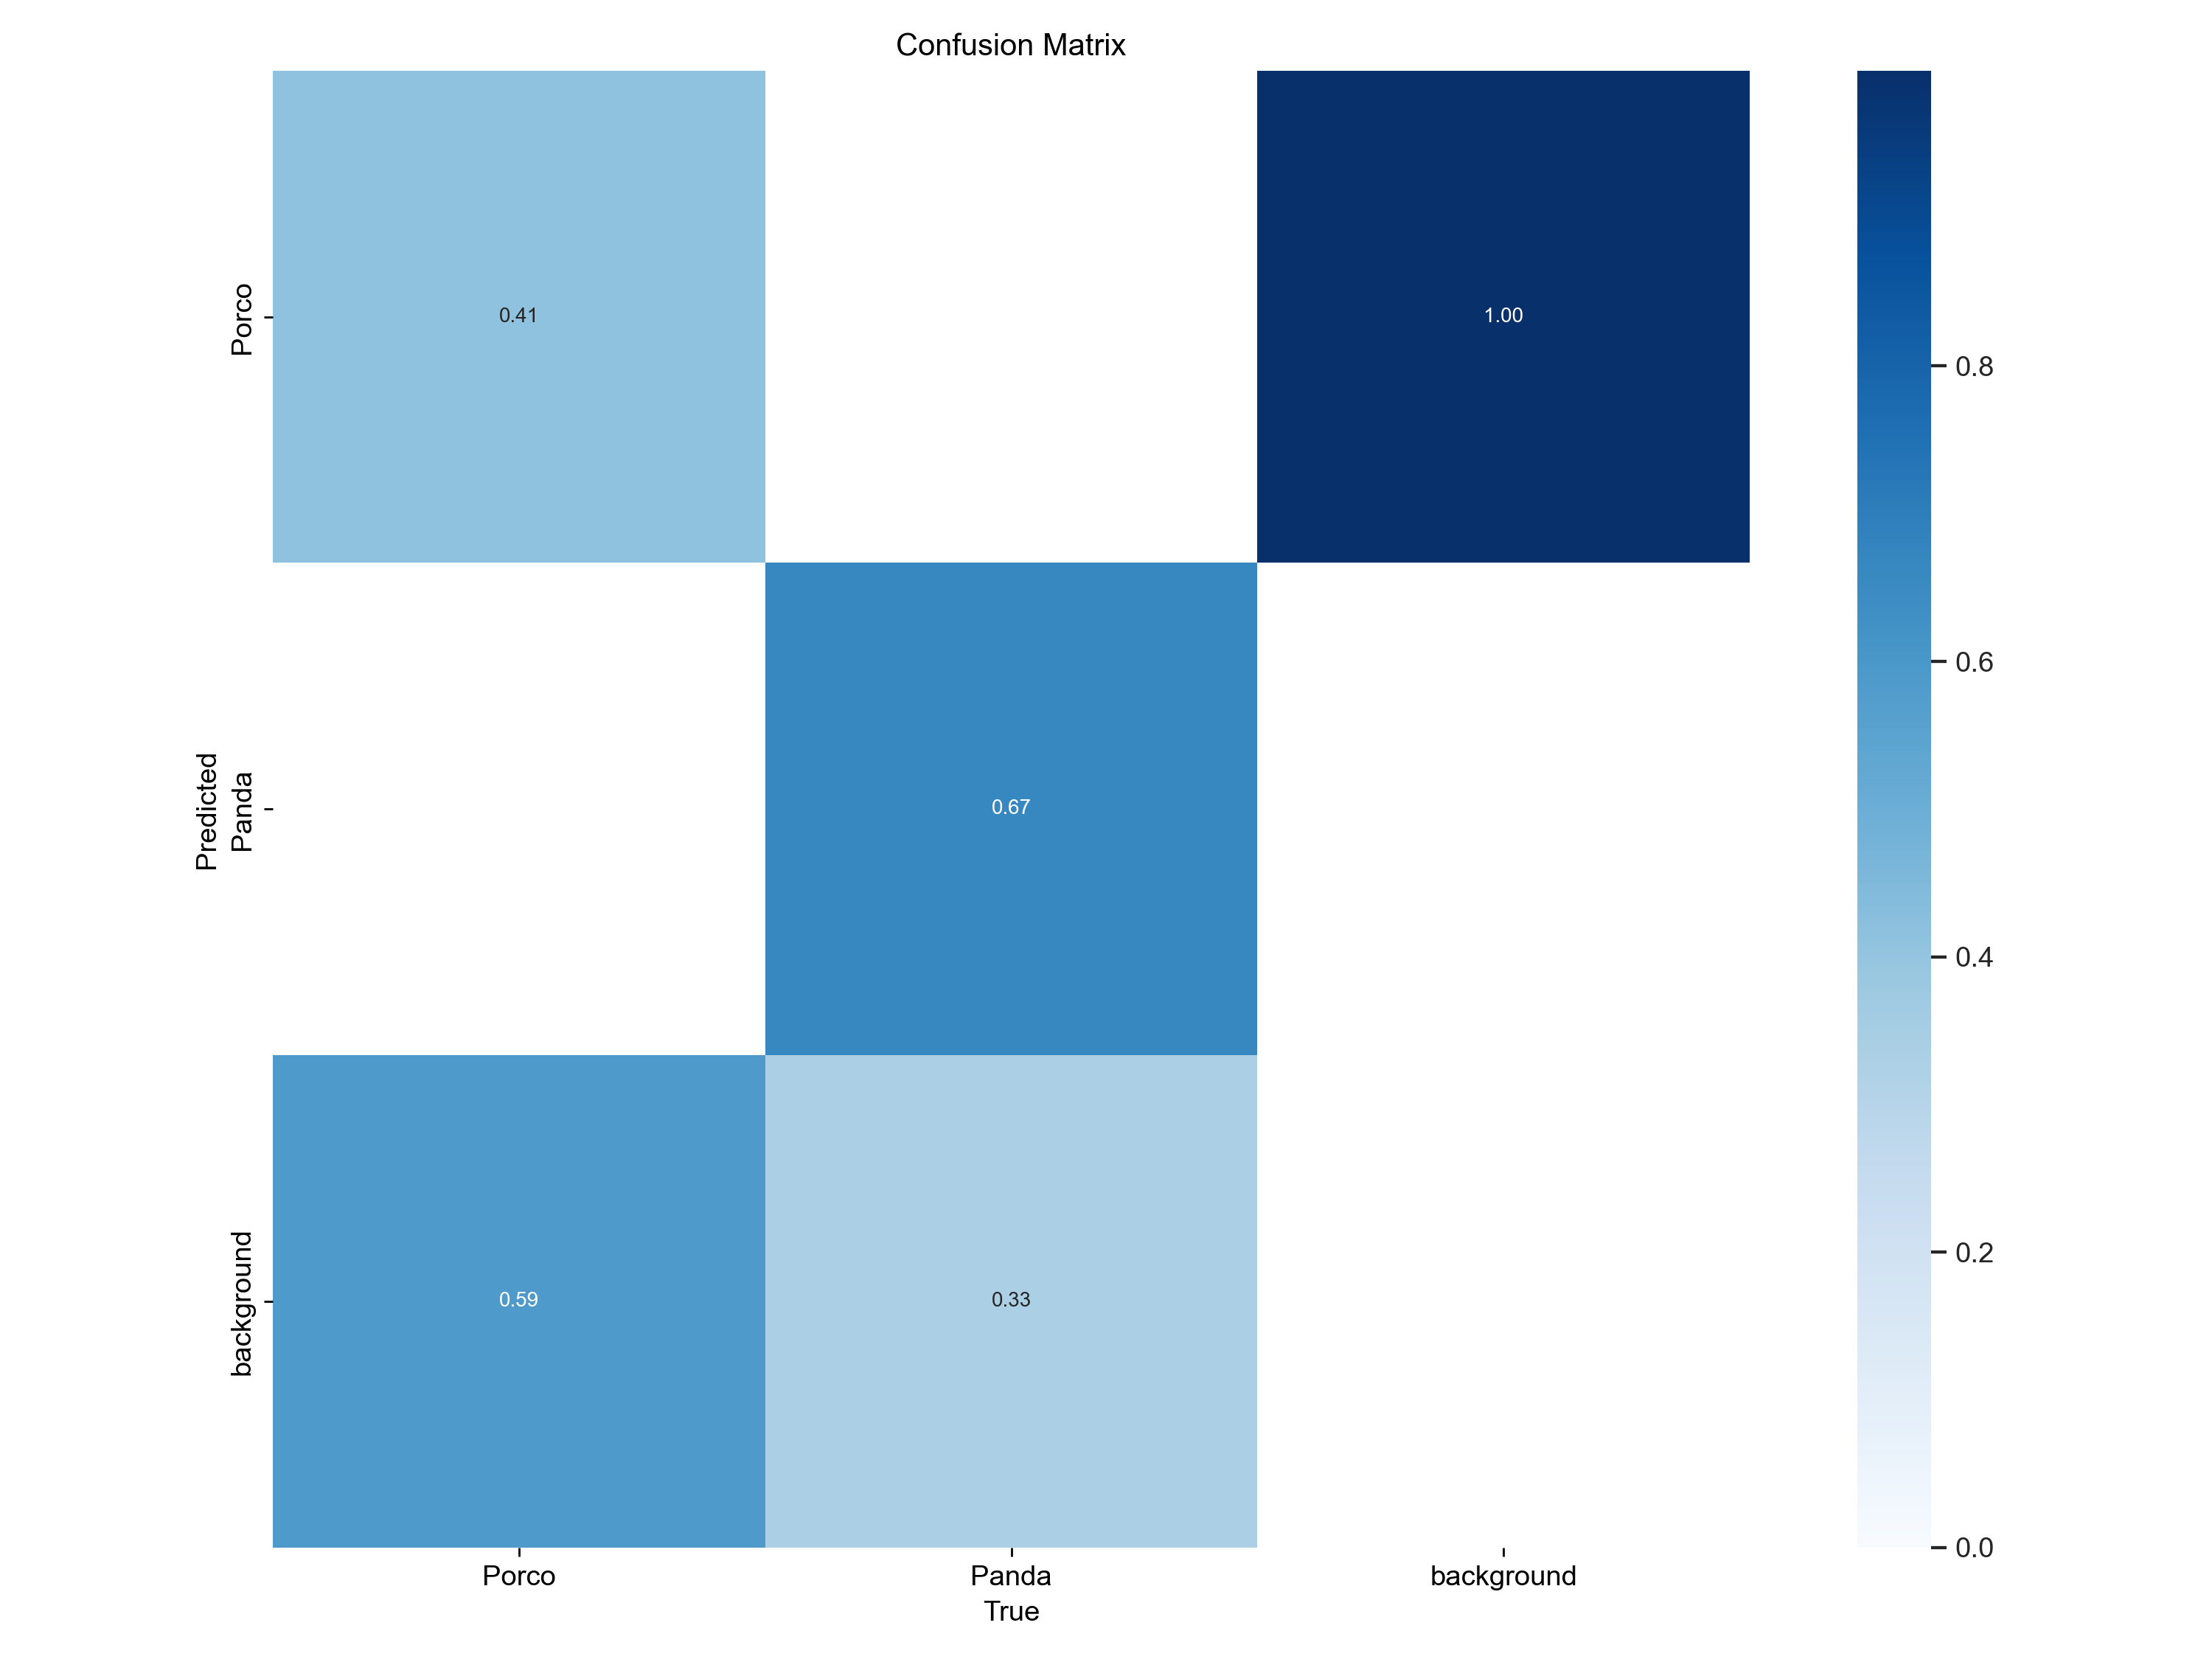

### Evolução do treinamento

Mostra perdas, precisão, recall e mAP ao longo das épocas.

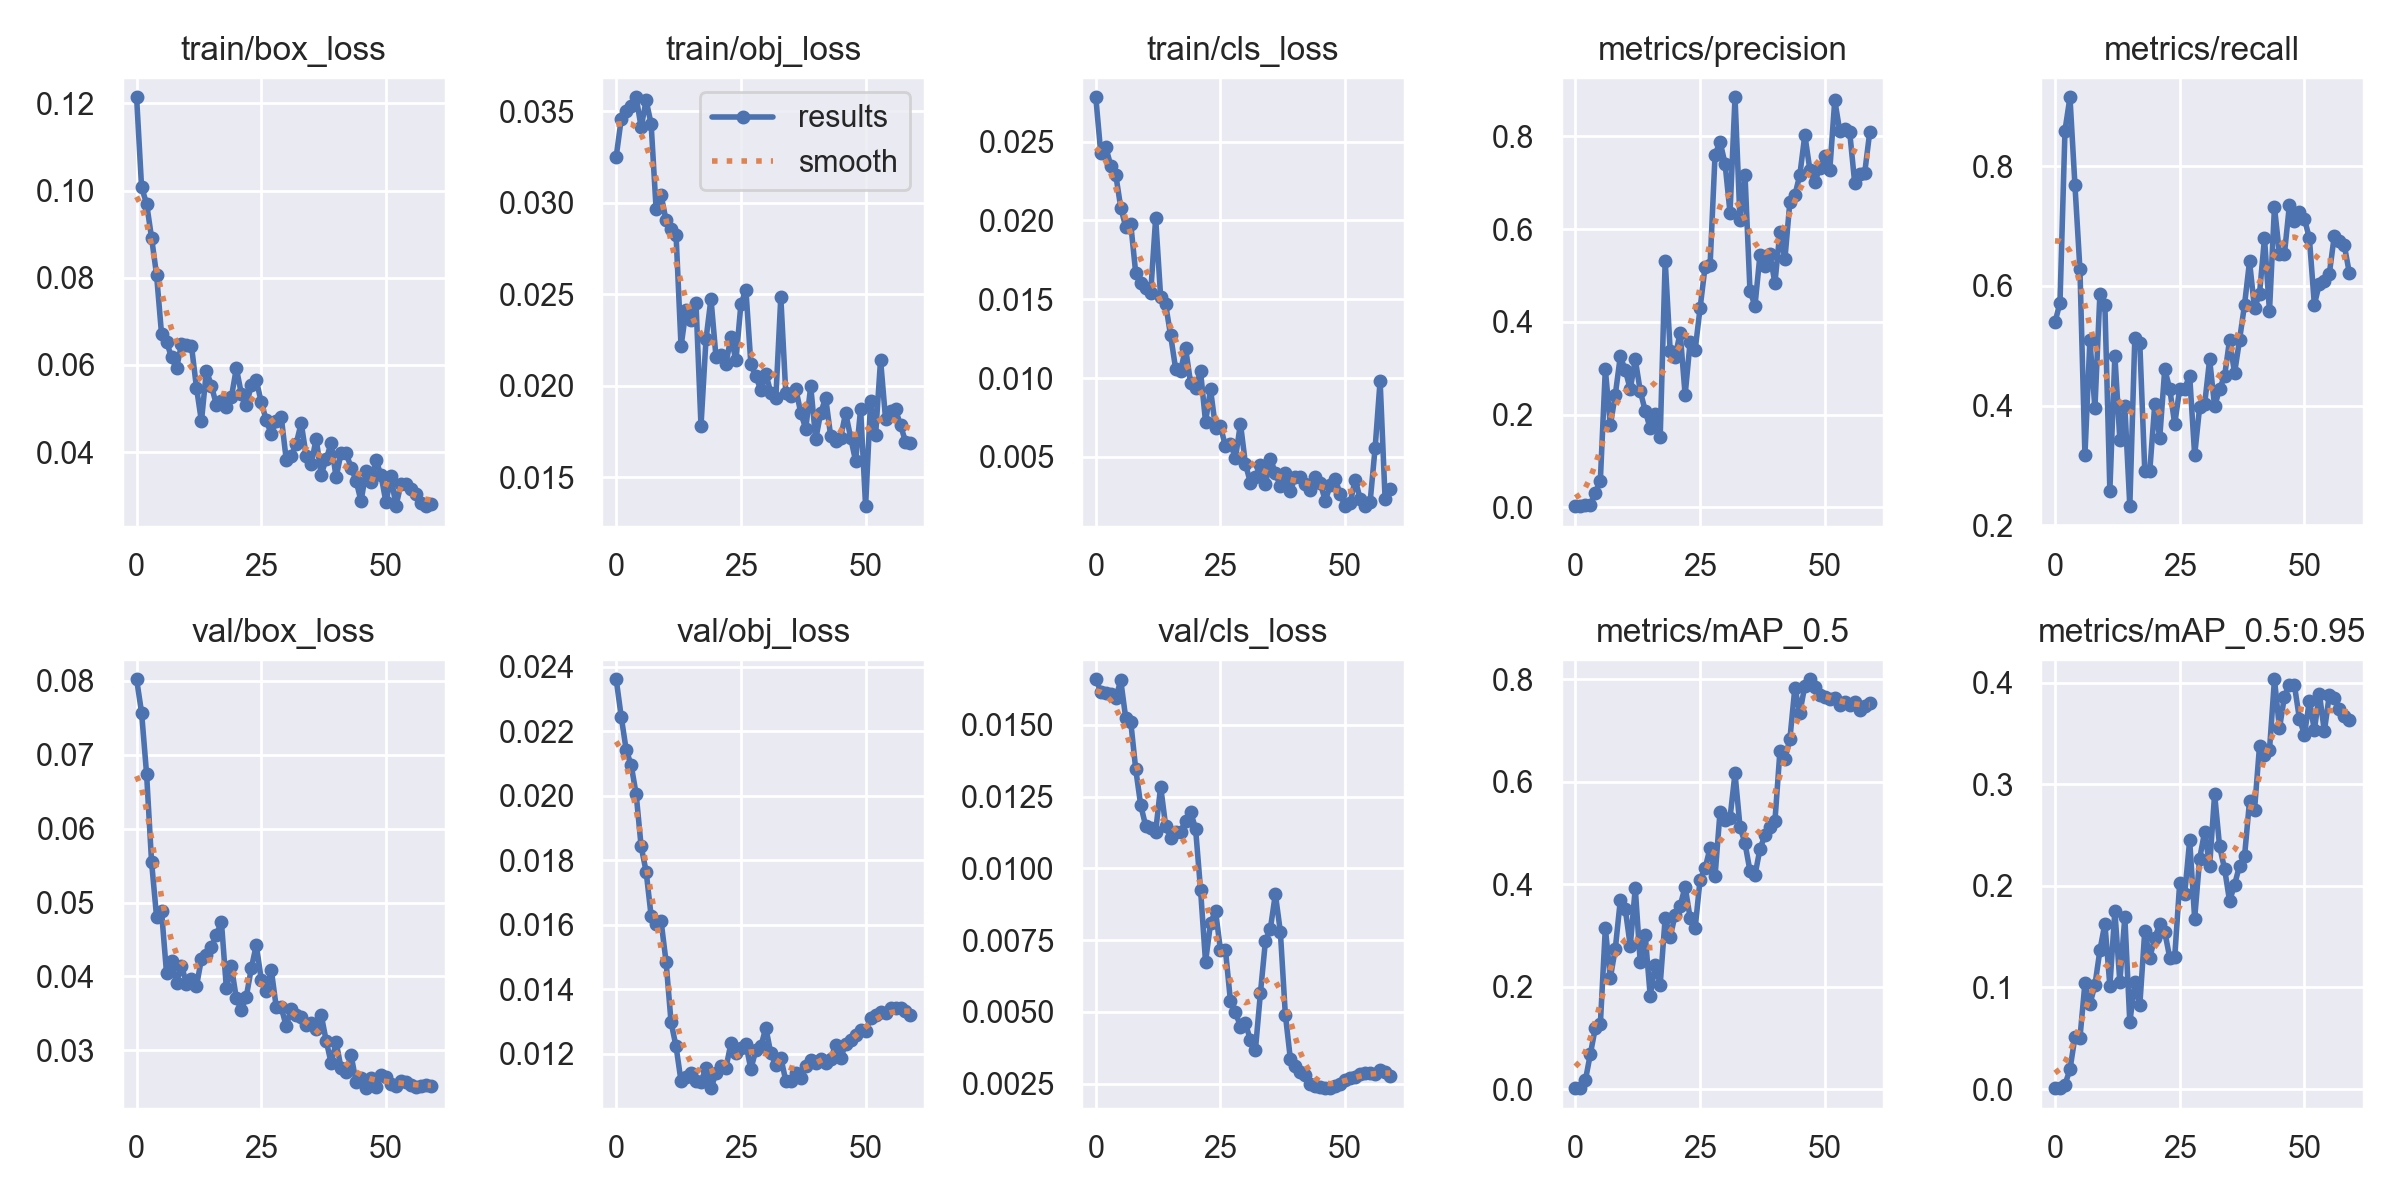

### Curva de precisão e recall

Apresenta o AP por classe e o mAP50 geral.

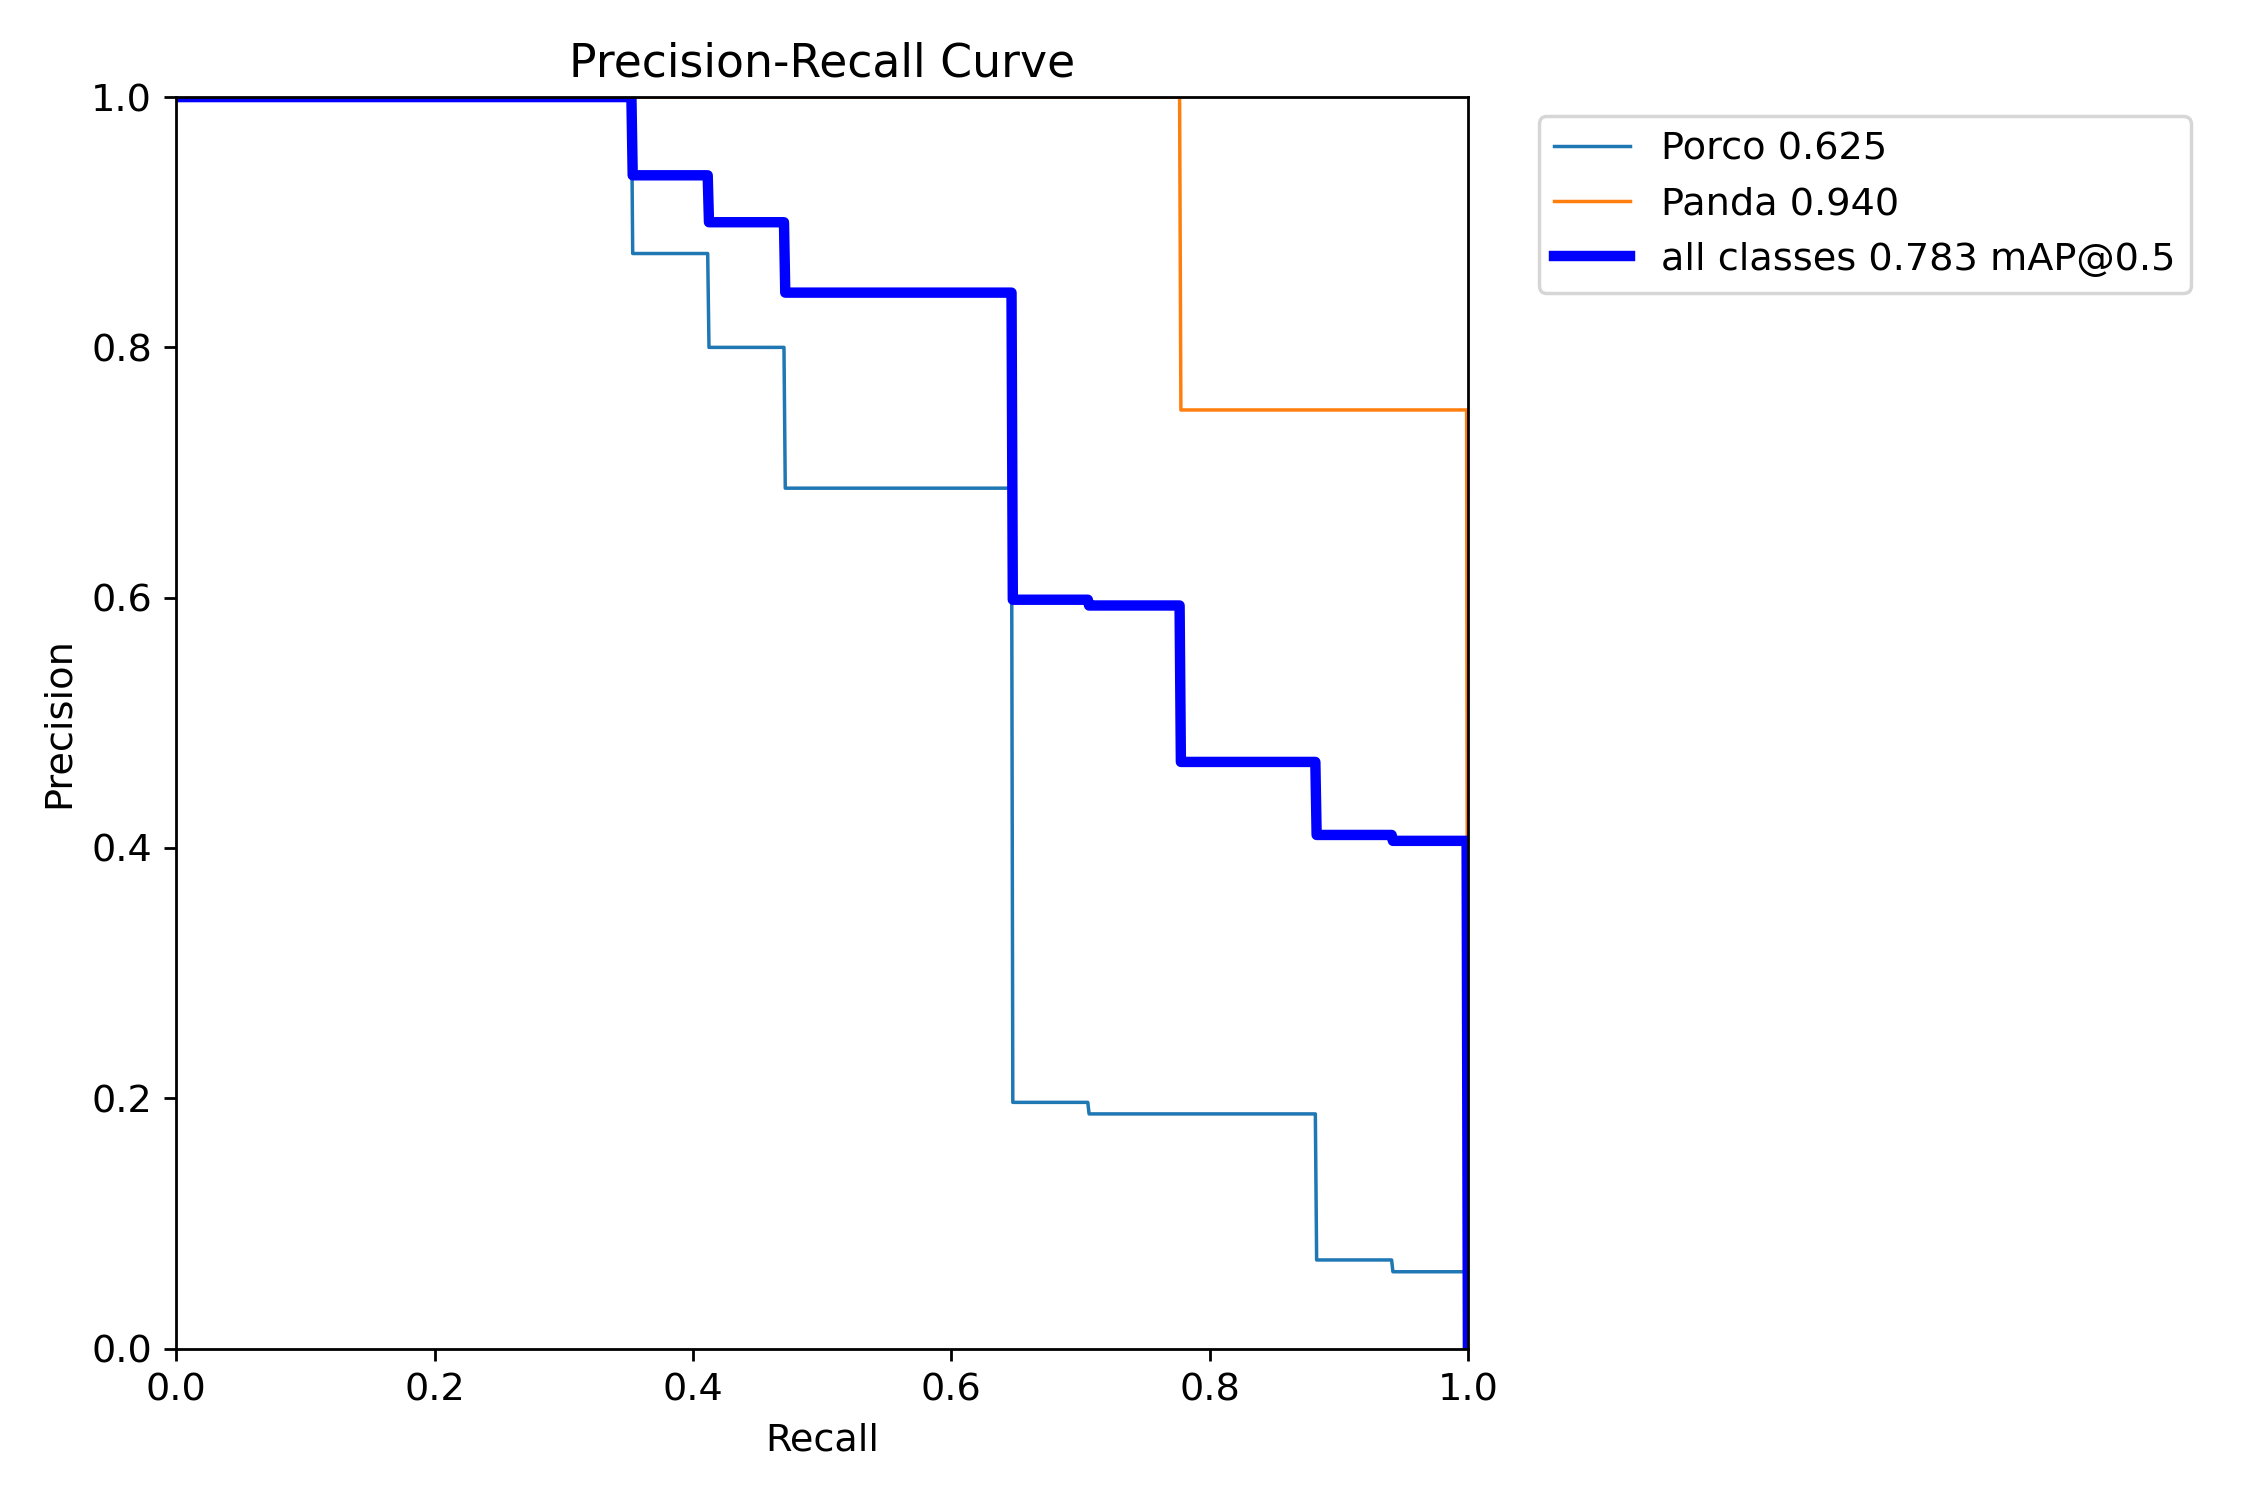

In [163]:
from IPython.display import Image, display, Markdown

pasta = '/content/yolov5/runs/train/exp2'

imagens = [
    ('confusion_matrix.png', 'Matriz de confusão',
     'Mostra acertos, confusões entre classes e falhas de detecção.'),

    ('results.png', 'Evolução do treinamento',
     'Mostra perdas, precisão, recall e mAP ao longo das épocas.'),

    ('PR_curve.png', 'Curva de precisão e recall',
     'Apresenta o AP por classe e o mAP50 geral.')
]

for arquivo, titulo, descricao in imagens:
    display(Markdown(f'### {titulo}\n\n{descricao}'))
    display(Image(filename=f'{pasta}/{arquivo}', width=800))

#Relatório de resultados e conclusões

### Achados
A CNN foi treinada do zero com 56 imagens por 10 épocas. A perda de treinamento caiu de 0,7335 para 0,2325. No teste, acertou **13 das 14 imagens**, com **92,86% de acurácia**, **7,14% de erro** e perda de **0,2403**.

### Pontos fortes e limitações
O modelo aprendeu a distinguir porcos e pandas sem pesos pré-treinados e apresentou bom resultado neste teste. Entretanto, o conjunto é pequeno e a validação não foi utilizada, limitando a análise de overfitting. A CNN classifica a imagem inteira, sem localizar os animais.

### Conclusão
Os resultados são promissores, mas não garantem o mesmo desempenho em novas imagens. Ampliar o dataset, acompanhar a validação e avaliar mais exemplos independentes são os próximos passos.


# Avaliação crítica: CNN do zero e YOLO

Comparação baseada nas saídas salvas.

| Critério | CNN do zero | YOLO adaptado |
|---|---|---|
| **Facilidade de uso/integração** | Integração com TensorFlow/Keras; exige definir arquitetura e preparar os dados. Classifica a imagem inteira. | Scripts prontos facilitam treinamento e detecção; requer configuração e anotações de caixas. Localiza e classifica vários objetos. |
| **Precisão do modelo** | Acurácia de **92,86% no teste**: 13 acertos em 14 imagens. Não foi calculada precisão por classe. | Com 60 épocas, obteve **84,3% de precisão**, **62,4% de recall** e **77,3% de mAP50 na validação**. |
| **Tempo de treinamento/customização** | 10 épocas, com aproximadamente **1 a 3 segundos por época** nos logs. Arquitetura construída manualmente. | Os logs registram cerca de **29 segundos para 30 épocas** e **25 segundos para 60 épocas**, partindo de pesos pré-treinados. O tempo de preparação e anotação não foi medido. |
| **Tempo de inferência** | Não foi medido; não é possível afirmar que seja mais rápida. | **6,9 ms/imagem** no modelo de 30 épocas e **5,9 ms/imagem** no de 60, sem incluir pré-processamento e NMS. |

**Conclusão:** a CNN atende à classificação entre porco e panda; o YOLO também atende à localização dos animais. Acurácia e mAP não são equivalentes, e os conjuntos avaliados são diferentes, portanto os números não demonstram superioridade de um modelo. O dataset pequeno e a ausência de validação no treino da CNN limitam as conclusões. Os tempos registrados não são uma comparação controlada: seria necessário repetir as medições no mesmo ambiente e nas mesmas condições.
